GeoQubit 

Run:  python geoqubit_simple.py        (needs: numpy scipy matplotlib qiskit)

In [12]:
%pip install -q numpy pandas matplotlib scipy scikit-learn qiskit qiskit-aer qiskit-machine-learning qiskit-ibm-runtime pylatexenc

In [24]:
%matplotlib inline
import numpy as np
from scipy.optimize import minimize, least_squares
from scipy.integrate import quad
from scipy.special import j0
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
import matplotlib
import matplotlib.pyplot as plt

1. ADVANCED PHYSICS FOR PARMETERS

In [14]:
RHO1 = 100.0
A_SP = np.logspace(0, np.log10(50), 12)          # Wenner spacings 1-50 m

def n_terms(k, tol=1e-8):
    """Dynamically calculates the number of image terms needed for desired tolerance."""
    k = abs(k)
    if k < 1e-12: return 1
    return int(np.clip(np.ceil(np.log(tol * (1 - k) / 2) / np.log(k)), 20, 5000))

def rho_a(a, rho1, k, h, N=None):
    """Wenner apparent resistivity using adaptive image theory."""
    a = np.atleast_1d(np.asarray(a, float))
    N = N or n_terms(k)
    n = np.arange(1, N + 1)[:, None]
    t = 2 * n * h / a[None, :]
    s = (k ** n) * (1/np.sqrt(1 + t**2) - 1/np.sqrt(4 + t**2))
    return rho1 * (1 + 4 * s.sum(axis=0))

def rho_a_hankel(a, rho1, k, h):
    """Exact 2-layer Wenner apparent resistivity via Hankel transform (Bessel function integration)."""
    out = []
    for ai in np.atleast_1d(a):
        f = lambda l: (k * np.exp(-2 * l * h) / (1 - k * np.exp(-2 * l * h))) * (j0(l * ai) - j0(2 * l * ai))
        up = 60.0 / h
        val, _ = quad(f, 0, up, limit=2000, epsabs=1e-13, epsrel=1e-12)
        out.append(rho1 * (1 + 4 * ai * val))
    return np.array(out)

2. QUNATUM CIRCUIT

In [15]:
NQ, L = 3, 3
theta = ParameterVector("t", 2 * NQ * L)
qc = QuantumCircuit(NQ)
i = 0
for _ in range(L):
    for q in range(NQ):
        qc.ry(theta[i], q)
        qc.rz(theta[i+1], q)
        i += 2
    for q in range(NQ):
        qc.cx(q, (q + 1) % NQ)

# Define explicit Pauli-Z observables for each qubit
Zops = [SparsePauliOp("I" * (NQ - 1 - q) + "Z" + "I" * q) for q in range(NQ)]
KMAX, HMIN, HMAX = 0.95, 1.0, 30.0

def decode_z(z):
    """Maps qubit expectation values to physical bounds for reflection coefficient k and depth h."""
    return KMAX * z[0], HMIN + (HMAX - HMIN) * (1 + z[1]) / 2

def expZ(x):
    """Computes exact expectation values of Z operators using Statevector."""
    sv = Statevector(qc.assign_parameters(x))
    return np.array([sv.expectation_value(op).real for op in Zops])

def z_from_counts(counts):
    """Extracts Z expectation values from finite-shot measurement counts."""
    shots = counts.sum()
    z = []
    for q in range(NQ):
        bit = (np.arange(len(counts)) >> q) & 1
        z.append(((1 - 2 * bit) * counts).sum() / shots)
    return np.array(z)

def misfit(pred, target):
    """Mean squared error of log10 resistivity."""
    return np.mean((np.log10(pred) - np.log10(target))**2)

3. EXECUTION

In [16]:
if __name__ == "__main__":
    K_TRUE, H_TRUE = 0.6, 8.0
    # Generate synthetic target data using the exact Hankel transform
    target_data = rho_a_hankel(A_SP, RHO1, K_TRUE, H_TRUE)
    rng = np.random.default_rng(42)

    best, evals = None, 0
    for start in range(5):
        def cost(x):
            z = expZ(x)
            k, h = decode_z(z)
            pred = rho_a(A_SP, RHO1, k, h)
            return misfit(pred, target_data)

        result = minimize(cost, rng.normal(0, 0.3, len(theta)), method="COBYLA", options={"maxiter": 600})
        evals += result.nfev
        print(f"Quantum start {start + 1}: misfit = {result.fun:.1e}")
        if best is None or result.fun < best.fun:
            best = result

    k_q, h_q = decode_z(expZ(best.x))

    # Classical least-squares baseline
    ls = least_squares(lambda p: np.log10(rho_a(A_SP, RHO1, *p)) - np.log10(target_data),
                       x0=[0.0, 10.0], bounds=([-0.95, 1], [0.95, 30]))

    print(f"\nTrue Parameters : k = {K_TRUE:.3f}, h = {H_TRUE:.2f} m")
    print(f"Quantum Fit     : k = {k_q:.3f}, h = {h_q:.2f} m  ({evals} evaluations)")
    print(f"Classical Fit   : k = {ls.x[0]:.3f}, h = {ls.x[1]:.2f} m  ({ls.nfev} evaluations)")

   # --- Plotting results and displaying them ---
    a_fine = np.logspace(0, np.log10(50), 100)

    plt.figure(figsize=(6, 4))
    plt.loglog(A_SP, target_data, "ko", label="Target Data (Hankel)")
    plt.loglog(a_fine, rho_a_hankel(a_fine, RHO1, k_q, h_q), "-", label="Quantum Fit")
    plt.xlabel("SpA (m)")
    plt.ylabel("Apparent Resistivity (Omega-m)")
    plt.title("GeoQubit Inversion Fit")
    plt.legend()
    plt.tight_layout()

    # Save the file (optional)
    plt.savefig("geoqubit_upgraded_fit.png", dpi=200)

    plt.show()

Quantum start 1: misfit = 4.7e-13
Quantum start 2: misfit = 5.7e-09
Quantum start 3: misfit = 3.9e-12
Quantum start 4: misfit = 3.3e-10
Quantum start 5: misfit = 4.8e-13

True Parameters : k = 0.600, h = 8.00 m
Quantum Fit     : k = 0.600, h = 8.00 m  (1590 evaluations)
Classical Fit   : k = 0.600, h = 8.00 m  (7 evaluations)


PLOT 1: PLOT 1: SOUNDING CURVES & HANKEL CHECK (Figure 1a style)

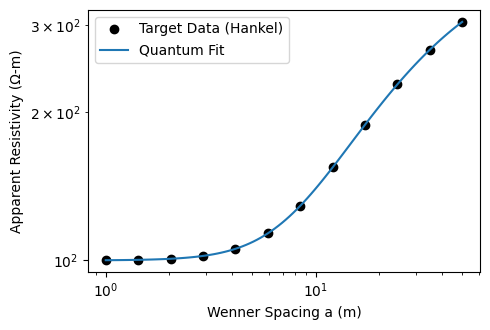

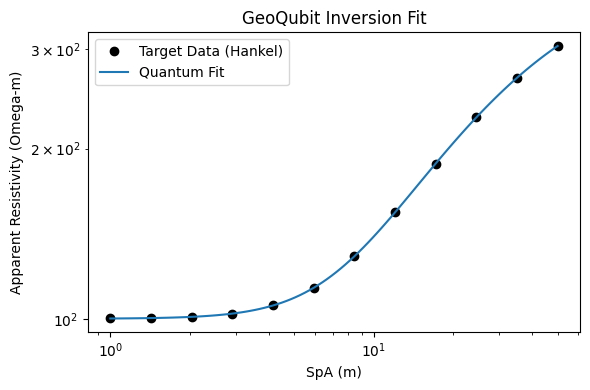

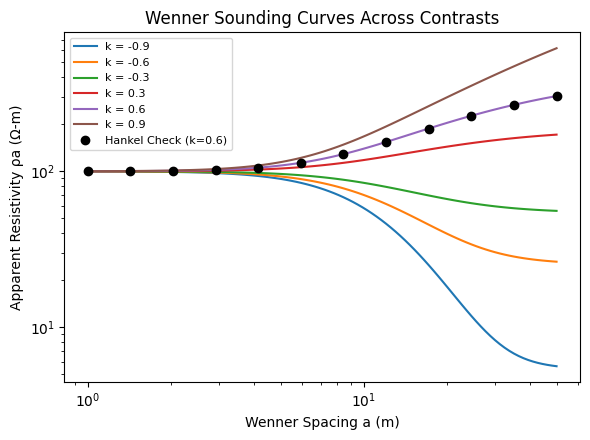

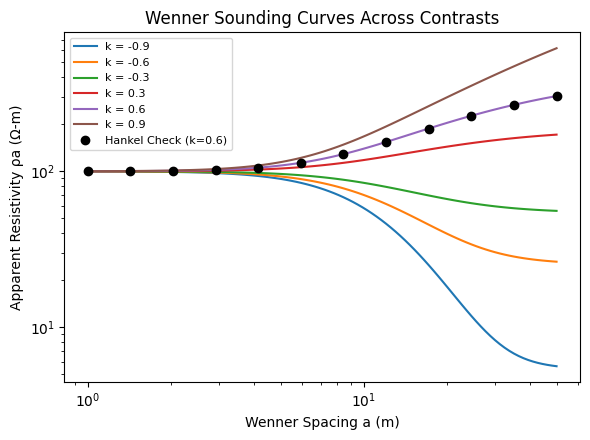

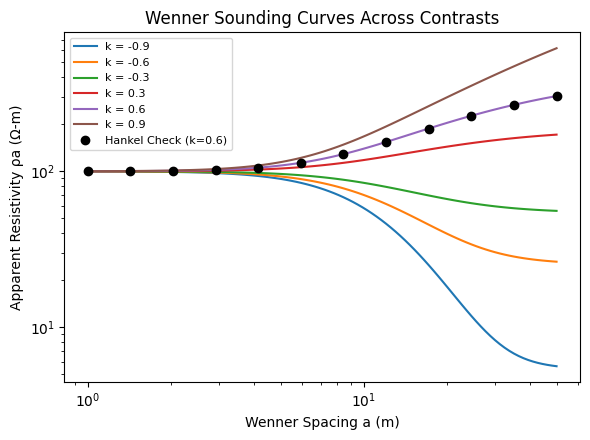

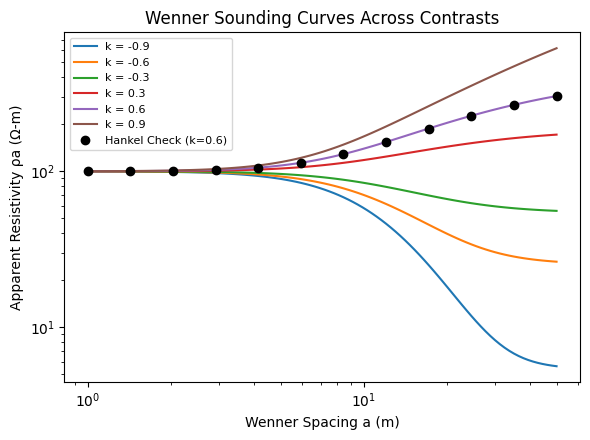

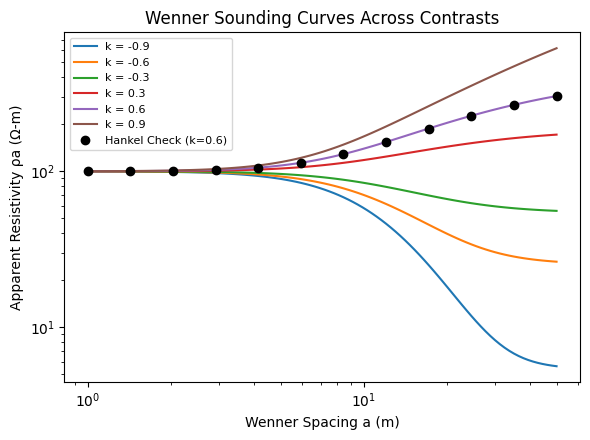

In [25]:
plt.figure(figsize=(6, 4.5))
a_fine = np.logspace(0, np.log10(50), 100)
contrasts = [-0.9, -0.6, -0.3, 0.3, 0.6, 0.9]

for kc in contrasts:
  curve = rho_a(a_fine, RHO1, kc, H_TRUE)
  plt.loglog(a_fine, curve, label=f"k = {kc}")

    # Overlay Hankel check points for k=0.6
hankel_check_pts = rho_a_hankel(A_SP, RHO1, 0.6, H_TRUE)
plt.loglog(A_SP, hankel_check_pts, "ko", label="Hankel Check (k=0.6)")

plt.xlabel("Wenner Spacing a (m)")
plt.ylabel("Apparent Resistivity ρa (Ω-m)")
plt.title("Wenner Sounding Curves Across Contrasts")
plt.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


PLOT 2: CONVERGENCE CURVE (Figure 1b style)


In [27]:
convergence_history = []
best, evals = None, 0

for start in range(3):
    history = []
    def cost(x):
        z = expZ(x)
        k, h = decode_z(z)
        pred = rho_a(A_SP, RHO1, k, h)
        val = misfit(pred, target_data)
        history.append(val)
        return val

    result = minimize(cost, np.random.default_rng(42).normal(0, 0.3, 2 * NQ * L), method="COBYLA", options={"maxiter": 400})
    evals += result.nfev
    convergence_history.append(history)
    if best is None or result.fun < best.fun:
        best = result

print("Optimization complete! Now you can run your plotting cell.")

Optimization complete! Now you can run your plotting cell.


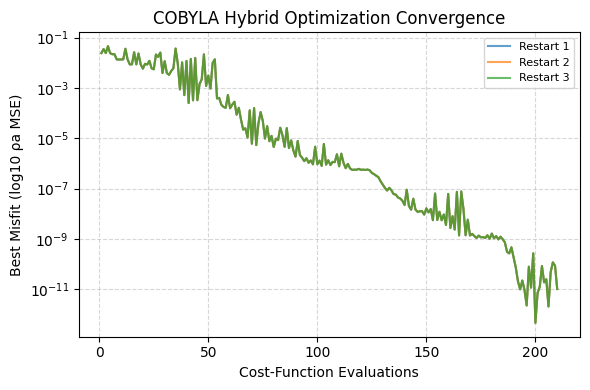

In [28]:
plt.figure(figsize=(6, 4))
for idx, hist in enumerate(convergence_history):
  plt.plot(range(1, len(hist) + 1), hist, alpha=0.7, label=f"Restart {idx+1}")

plt.yscale("log")
plt.xlabel("Cost-Function Evaluations")
plt.ylabel("Best Misfit (log10 ρa MSE)")
plt.title("COBYLA Hybrid Optimization Convergence")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

PLOT 3: MISFIT LANDSCAPE / EQUIVALENCE VALLEY (Figure 2a style)

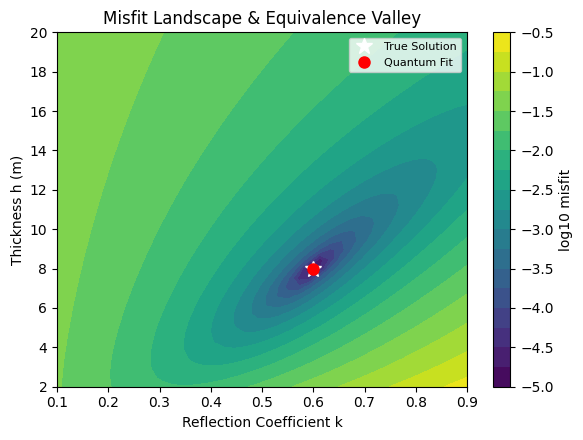

In [29]:
plt.figure(figsize=(6, 4.5))
k_grid = np.linspace(0.1, 0.9, 40)
h_grid = np.linspace(2.0, 20.0, 40)
K_mesh, H_mesh = np.meshgrid(k_grid, h_grid)
Z_misfit = np.zeros_like(K_mesh)

for r in range(K_mesh.shape[0]):
  for c in range(K_mesh.shape[1]):
      pred_grid = rho_a(A_SP, RHO1, K_mesh[r, c], H_mesh[r, c])
      Z_misfit[r, c] = np.log10(misfit(pred_grid, target_data))

contour = plt.contourf(K_mesh, H_mesh, Z_misfit, levels=20, cmap="viridis")
plt.colorbar(contour, label="log10 misfit")
plt.plot(K_TRUE, H_TRUE, "w*", markersize=12, label="True Solution")
plt.plot(k_q, h_q, "ro", markersize=8, label="Quantum Fit")

plt.xlabel("Reflection Coefficient k")
plt.ylabel("Thickness h (m)")
plt.title("Misfit Landscape & Equivalence Valley")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()